In [12]:
import numpy as np
from spidercat.benchmark import benchmark_circuit
from spidercat.utils import load_solution_triplet
from spidercat.spanning_tree import match_forest_leaves_to_marked_edges, inject_root_nodes
from spidercat.circuit_extraction import expand_graph_and_forest, build_traversal_digraph, extract_from_expanded_graph
from spidercat.fault_analysis import compute_boundary_fault_table, build_graph_dem
from spidercat.draw import draw_forest_on_graph
from spidercat.draw import display_digraph_on_graph
from spidercat.circuit_extraction import build_traversal_digraph
from spidercat.weight_optimization import (
    exhaustive_weight_search,
    greedy_weight_search,
    simulated_annealing_weight_search
)


%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


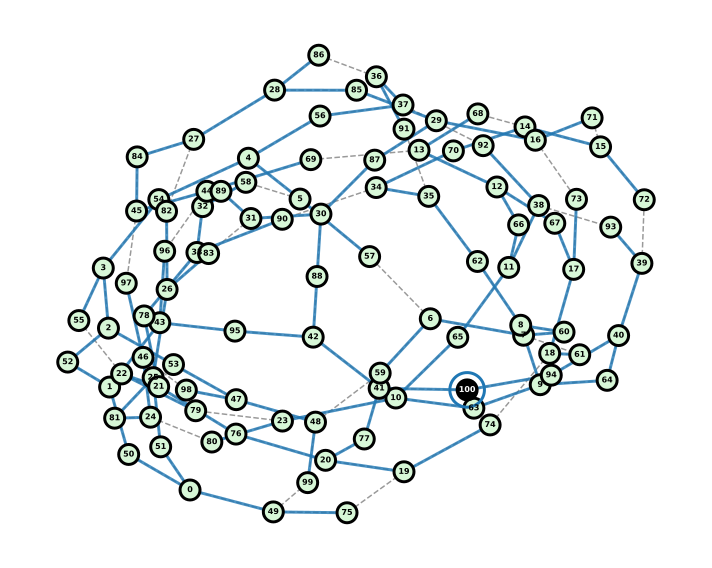

In [54]:
n, t = 50, 5

grf, forest, M, matchings = load_solution_triplet(n, t, 1)
matchings = match_forest_leaves_to_marked_edges(grf, forest, M)
G_exp, F_exp = expand_graph_and_forest(grf, forest, M, matchings)
roots = inject_root_nodes(G_exp, F_exp)
draw_forest_on_graph(G_exp, F_exp, roots)

In [55]:
dem = build_graph_dem(G_exp, F_exp, root=roots[0], cycle_basis_mode="fundamental")
for e in dem.edges:
    detectors, logicals = dem.edge_targets(e)
    print(f"Edge {e}: D{detectors}, L{logicals}")

Edge (0, 49): D[8, 25], L[25]
Edge (0, 50): D[8, 11, 12, 13, 22, 23, 25], L[1, 25, 31, 32, 33, 47]
Edge (0, 51): D[11, 12, 13, 22, 23], L[1, 31, 32, 33, 47]
Edge (1, 43): D[0, 1, 8, 9, 11, 12, 13, 16, 17, 18, 22, 24], L[0, 1, 2, 3, 4, 5, 6, 7, 25, 31, 32, 33, 41, 47, 48, 49]
Edge (1, 50): D[8, 11, 12, 13, 22, 23, 25], L[0, 1, 25, 31, 32, 33, 47]
Edge (1, 52): D[0, 1, 9, 16, 17, 18, 23, 24, 25], L[2, 3, 4, 5, 6, 7, 41, 48, 49]
Edge (2, 3): D[0, 1, 9, 16, 17, 18], L[4, 5, 6, 7, 41]
Edge (2, 52): D[0, 1, 9, 16, 17, 18, 23, 24, 25], L[3, 4, 5, 6, 7, 41, 48, 49]
Edge (2, 53): D[23, 24, 25], L[3, 48, 49]
Edge (3, 54): D[0, 1, 16, 17, 18], L[4, 6, 7, 41]
Edge (3, 55): D[9], L[5]
Edge (4, 5): D[0, 1], L[7]
Edge (4, 54): D[0, 1, 16, 17, 18], L[6, 7, 41]
Edge (4, 56): D[16, 17, 18], L[6, 41]
Edge (5, 57): D[1], L[7]
Edge (6, 7): D[1, 24], L[9]
Edge (6, 59): D[24], L[9]
Edge (7, 60): D[1, 2, 24], L[9]
Edge (8, 9): D[1, 2, 4, 5, 15, 16, 20, 24], L[9, 10, 12, 20, 22]
Edge (8, 60): D[1, 2, 24], L[9,

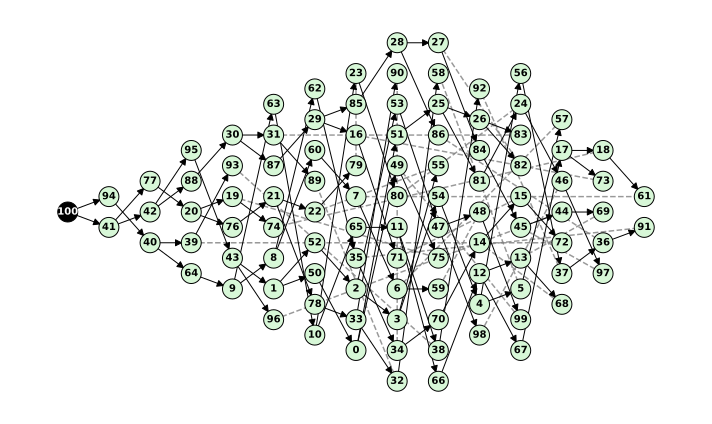

In [56]:
digraph = build_traversal_digraph(G_exp, F_exp, roots[0])
display_digraph_on_graph(digraph, G_exp, figsize=(10, 6))

In [57]:
table = compute_boundary_fault_table(G_exp, F_exp, L=5, root=roots)
print("Table build")

Table build


In [58]:
# candidates = exhaustive_weight_search(table, fix_boundary_weight_one=True)
# print("Best exhaustive:    ", candidates[0].polynomial_str)
# print("Worst exhaustive:   ", candidates[-1].polynomial_str)
# print("Edge weights:", candidates[0].edge_weights)  # flag edges are (w_a, w_b) tuples

# 2. Greedy search
greedy_cand = greedy_weight_search(table, fix_boundary_weight_one=True)
print("Greedy:             ", greedy_cand.polynomial_str)

# 3. Simulated annealing (starting from greedy)
sa_cand = simulated_annealing_weight_search(table, fix_boundary_weight_one=True, num_steps=1_000)
print("Simulated Annealing:", sa_cand.polynomial_str)

Greedy:              50p + 1225p^2 + 19600p^3 + 230576p^4 + 2133928p^5
Simulated Annealing: 50p + 1225p^2 + 19600p^3 + 230576p^4 + 2133928p^5


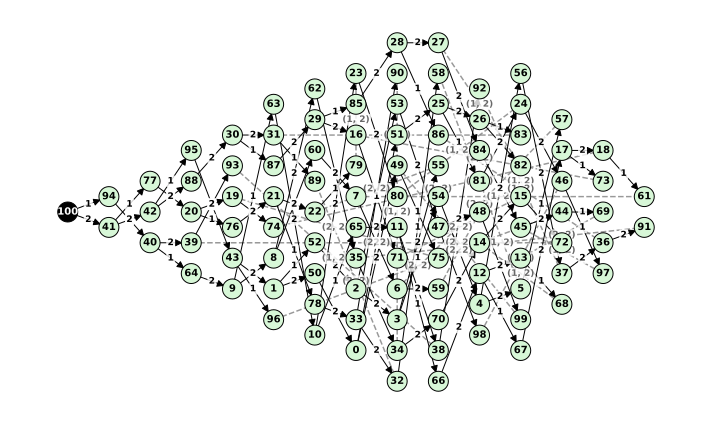

In [59]:
display_digraph_on_graph(digraph, G_exp, weights=sa_cand.edge_weights, figsize=(10, 6))

In [60]:
circ = extract_from_expanded_graph(G_exp, F_exp, roots, weights=sa_cand, dependency_graph=digraph)
circ.diagram('timeline-svg')

RuntimeError: Flag edge (23, 79) already in edge_to_flag when processing weight-1 endpoint 23. Ensure dependency_graph orders weight-1 endpoint before weight-2 endpoint.

In [52]:
stats_opt = benchmark_circuit(circ, n, num_samples=10_000_000, p=0.01)
print("\nExpected number of faults for optimized circuit:", sum(k * v for k, v in stats_opt.items()))

Stats for 50-cat (p=0.05): {0: 0.44652805592979644, 1: 0.3561883261114955, 2: 0.1453045916323781, 3: 0.04034519171248589, 4: 0.009066744346939519, 5: 0.0020755197902632633, 6: 0.0003459199650438772, 7: 1.820631394967775e-05, 8: 9.103156974838874e-05, 9: 1.820631394967775e-05, 10: 1.820631394967775e-05}

Expected number of faults for optimized circuit: 0.8177547973637257


In [53]:
circ_og = extract_from_expanded_graph(G_exp, F_exp, roots)
stats_og = benchmark_circuit(circ_og, n, num_samples=10_000_000, p=0.05)
print("\nExpected number of faults for the original circuit:", sum(k * v for k, v in stats_og.items()))

Stats for 50-cat (p=0.05): {0: 0.44127946005769547, 1: 0.36137670773082714, 2: 0.14436562222181903, 3: 0.040441243173612494, 4: 0.009797340203566958, 5: 0.0021771867119037684, 6: 0.0004354373423807537, 7: 9.071611299599035e-05, 8: 1.814322259919807e-05, 9: 1.814322259919807e-05}

Expected number of faults for the original circuit: 0.8250630476985322
